# Reproducing the four-skill Soccer Factor Model

This notebook fits the model behind [Football Skills with Wyatt](https://examinedalgorithms.com/football_models_with_wyatt/) from a single table, in plain PyMC. It shows the data, the model, a prior check, the fit, a predictive check, skill above replacement (SAR), and a parameter-recovery test. The [write-up](https://examinedalgorithms.com/football_models_with_wyatt/model.html) explains the choices. It adapts the Soccer Factor Model of Andorra and Göbel ([2024](https://arxiv.org/abs/2412.05911)).

The table, `data/model_table.csv`, has one row per player-season for 593 forwards in the top five European leagues, 2014/15 to 2023/24. It is built from Understat data (via the Kaggle archive `mexwell/understat-database`) and football-data.co.uk results by the scripts in `scripts/`. Run from the `football_models_with_wyatt/` folder with the environment in `environment.yml`. The two fits take about five minutes each.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import warnings

warnings.filterwarnings("ignore", message='install "ipywidgets"')

SEED = 2024
SAMPLE = dict(draws=1500, tune=1500, chains=4, target_accept=0.95, nuts_sampler="nutpie", random_seed=SEED, progressbar=False)
SKILLS = ["shoot", "fox", "sniper", "create"]
LEAGUES = ["EPL", "La_liga", "Bundesliga", "Serie_A", "Ligue_1"]

## The data

Each row is one player-season with at least 270 minutes. The columns the model uses:

- `minutes`, `np_shots`, `npxG`, `npg`, `key_passes`: season totals, without penalties.
- `team_strength`: the team's points-per-game gap to each opponent, measured before kickoff and averaged over the season.
- `season_index`: the number of seasons the player has been in the data so far.
- `fin_goals`, `fin_xg`, `fin_var`: goals, total xG and $\sum p(1-p)$ over the season's non-penalty shots, where $p$ is each shot's xG. These three numbers are all the finishing model needs.

In [2]:
df = pd.read_csv("data/model_table.csv")
print(f"{len(df):,} player-seasons, {df.player_id.nunique()} players")
df.head()

3,950 player-seasons, 593 players


,player_id,player,league,season,team,minutes,season_index,team_strength,np_shots,npxG,npg,key_passes,fin_goals,fin_xg,fin_var
0,11,Sandro Wagner,Bundesliga,2015,Darmstadt,2475,2,-0.3047,83,11.3248,12,28,12,11.32483,6.49116
1,11,Sandro Wagner,Bundesliga,2016,Hoffenheim,2608,3,0.3931,66,12.2280,11,17,11,12.22801,7.01140
2,11,Sandro Wagner,Bundesliga,2017,"Bayern Munich,Hoffenheim",1599,4,0.7348,52,9.0859,11,22,11,9.08587,5.07972
3,26,Salomon Kalou,Bundesliga,2014,Hertha Berlin,1858,1,-0.3376,47,5.7463,4,18,4,5.74628,4.27658
4,26,Salomon Kalou,Bundesliga,2015,Hertha Berlin,2546,2,0.2819,53,8.2146,12,21,12,8.21456,5.25871


Forwards at stronger teams score more. Part of that is the team, and part is that better forwards join better teams. The model has to separate the two.

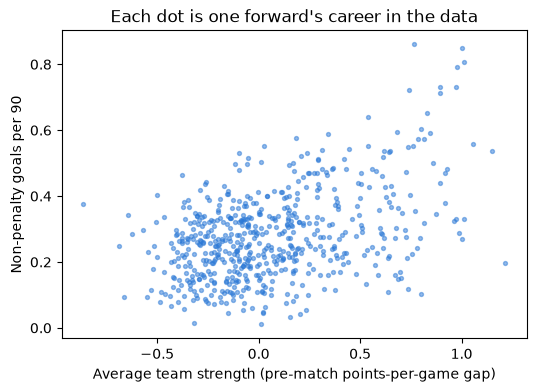

In [3]:
career = df.groupby("player_id").apply(
    lambda g: pd.Series({"ts": np.average(g.team_strength, weights=g.minutes),
                         "npg90": 90 * g.npg.sum() / g.minutes.sum()}), include_groups=False)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(career.ts, career.npg90, s=8, alpha=0.5, color="#2a78d6")
ax.set_xlabel("Average team strength (pre-match points-per-game gap)")
ax.set_ylabel("Non-penalty goals per 90")
ax.set_title("Each dot is one forward's career in the data")
plt.show()

## Indices and the Mundlak term

`tsbar` is each player's minutes-weighted average team strength, centred. Including it alongside the season's team strength is the Mundlak device: it absorbs the link between a player and the kind of team he plays for, so the team coefficient is learned from changes within careers.

In [4]:
pid = np.sort(df.player_id.unique())
p_idx = df.player_id.map({p: i for i, p in enumerate(pid)}).to_numpy()
l_idx = df.league.map({l: i for i, l in enumerate(LEAGUES)}).to_numpy()
names = df.groupby("player_id").player.first().reindex(pid).to_numpy()

tsbar_player = df.groupby("player_id").apply(
    lambda g: np.average(g.team_strength, weights=g.minutes), include_groups=False).reindex(pid).to_numpy()
tsbar_player = tsbar_player - tsbar_player[p_idx].mean()       # centre over player-seasons

data = dict(
    p=p_idx, l=l_idx, ts=df.team_strength.to_numpy(), tsbar_row=tsbar_player[p_idx], tsbar_player=tsbar_player,
    s_c=df.season_index.to_numpy(float) - 5.5, log_exp=np.log(df.minutes.to_numpy() / 90),
)
fox_rows = np.flatnonzero((df.np_shots > 0) & (df.npxG > 0))
fin_rows = np.flatnonzero(df.fin_var > 0)
observed = dict(
    np_shots=df.np_shots.to_numpy(),
    key_passes=df.key_passes.to_numpy(),
    log_xg_per_shot=np.log(df.npxG.to_numpy()[fox_rows] / df.np_shots.to_numpy()[fox_rows]),
    finishing=((df.fin_goals - df.fin_xg) / df.fin_var).to_numpy()[fin_rows],
)
n_shots_fox = df.np_shots.to_numpy()[fox_rows]
fin_sd = 1 / np.sqrt(df.fin_var.to_numpy()[fin_rows])
coords = {"player": names, "league": LEAGUES, "skill": SKILLS, "season": list(range(1, 11))}

## Finishing from three numbers a season

Shot $i$ has xG $p_i$ and goes in with probability $\text{logit}^{-1}(\text{logit}\,p_i + \eta)$, where $\eta$ is the forward's finishing that season. With $G$ the season's goals, the exact log-likelihood is

$$\ell(\eta) = G\,\eta - \sum_i \log\big(1 + e^{\text{logit}\,p_i + \eta}\big) + \text{const}.$$

The outcomes enter only through $G$. The xGs enter through the sum, whose first two derivatives at $\eta = 0$ are $X = \sum_i p_i$ and $V = \sum_i p_i(1-p_i)$. To second order,

$$\ell(\eta) \approx (G - X)\,\eta - \tfrac12 V\eta^2 + \text{const},$$

which is the log density of one normal observation $z = (G - X)/V$ with mean $\eta$ and standard deviation $1/\sqrt{V}$. So a season needs only `fin_goals`, `fin_xg` and `fin_var`. We write the likelihood as that normal observation, so the model can also simulate data. Here is what $z$ and its standard error look like for two forwards.

In [5]:
two = df[df.player.isin(["Lionel Messi", "Erling Haaland"])].assign(
    z=lambda d: (d.fin_goals - d.fin_xg) / d.fin_var,
    se=lambda d: 1 / np.sqrt(d.fin_var),
    V_over_X=lambda d: d.fin_var / d.fin_xg,
)
print(f"V / X over all seasons: {df.fin_var.sum() / df.fin_xg.sum():.2f}")
two[["player", "season", "team", "np_shots", "fin_goals", "fin_xg", "fin_var", "z", "se", "V_over_X"]].round(2)

V / X over all seasons: 0.66


,player,season,team,np_shots,fin_goals,fin_xg,fin_var,z,se,V_over_X
1825,Lionel Messi,2014,Barcelona,181,38,31.43,19.37,0.34,0.23,0.62
1826,Lionel Messi,2015,Barcelona,151,23,21.90,14.65,0.08,0.26,0.67
1827,Lionel Messi,2016,Barcelona,172,31,21.68,14.88,0.63,0.26,0.69
1828,Lionel Messi,2017,Barcelona,192,32,25.97,17.23,0.35,0.24,0.66
1829,Lionel Messi,2018,Barcelona,165,32,22.28,14.56,0.67,0.26,0.65
1830,Lionel Messi,2019,Barcelona,154,20,17.13,12.30,0.23,0.29,0.72
1831,Lionel Messi,2020,Barcelona,190,27,22.96,15.66,0.26,0.25,0.68
1832,Lionel Messi,2021,Paris Saint Germain,89,6,9.88,7.11,-0.55,0.37,0.72
1833,Lionel Messi,2022,Paris Saint Germain,129,16,17.66,11.59,-0.14,0.29,0.66
3859,Erling Haaland,2019,Borussia Dortmund,33,13,8.89,4.18,0.98,0.49,0.47


$V$ is how much a season can say about finishing. A 50% chance adds 0.25 to it, a 90% tap-in 0.09. A Poisson likelihood for goals with xG as exposure would take the variance of goals to be $X$, about half as much again as $V$, and would put real differences between finishers down to luck.

The table has no shot-level data, so to check the approximation we simulate a season of 120 shots with an xG mix like the real one (mean about 0.12) and compare the exact and quadratic log-likelihoods.

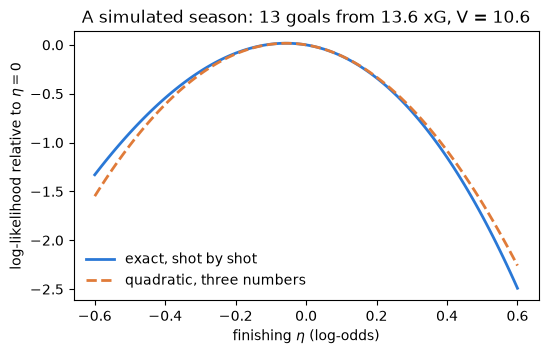

error at ±0.2: 0.0085, 0.0083 nats
error at ±0.4: 0.0685, 0.0658 nats


In [6]:
rng = np.random.default_rng(3)
p_sim = rng.beta(0.6, 4.2, size=120)
G_sim = rng.binomial(1, p_sim).sum()
X_sim, V_sim = p_sim.sum(), (p_sim * (1 - p_sim)).sum()

grid = np.linspace(-0.6, 0.6, 121)
exact = np.array([G_sim * e - np.log1p(np.exp(np.log(p_sim / (1 - p_sim)) + e)).sum() for e in grid])
exact -= exact[60]                                         # value at eta = 0
quad = (G_sim - X_sim) * grid - 0.5 * V_sim * grid**2

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(grid, exact, color="#2a78d6", lw=2, label="exact, shot by shot")
ax.plot(grid, quad, color="#e07b39", lw=2, ls="--", label="quadratic, three numbers")
ax.set_xlabel("finishing $\\eta$ (log-odds)")
ax.set_ylabel("log-likelihood relative to $\\eta = 0$")
ax.set_title(f"A simulated season: {G_sim} goals from {X_sim:.1f} xG, V = {V_sim:.1f}")
ax.legend(frameon=False)
plt.show()
for e in (0.2, 0.4):
    i = np.argmin(abs(grid - e)); j = np.argmin(abs(grid + e))
    print(f"error at ±{e}: {abs(exact[i] - quad[i]):.4f}, {abs(exact[j] - quad[j]):.4f} nats")

The two curves are hard to tell apart near zero, where most forwards' finishing lies. The error grows with the number of shots. This simulated season has 120, near the busiest real seasons. A typical real season has about 40, and its error at ±0.2 is about 0.002 nats.

## The model

For player-season $r$ and skill $k$:

$$\eta_{k,r} = \mu_k + \lambda_{k,\text{league}} + \beta_k\,\text{TS}_r + \gamma_k\,\overline{\text{TS}}_p + h_k(\text{season}) + \alpha_{p,k}$$

The four $\alpha$s are correlated with an LKJ prior. $h_k$ is a Matérn-5/2 HSGP career curve, with its basis centred over the data so its level cannot trade off against $\mu_k$. A player's skill is $\theta_{p,k} = \alpha_{p,k} + \gamma_k\,\overline{\text{TS}}_p$.

In [7]:
def hsgp_curve(name, s_c, m=8, c=2.0):
    ell = pm.InverseGamma(f"ell_{name}", alpha=5, beta=20)
    amp = pm.Exponential(f"amp_{name}", lam=1 / 0.15)
    gp = pm.gp.HSGP(m=[m], c=c, cov_func=amp**2 * pm.gp.cov.Matern52(1, ls=ell))
    grid = np.arange(1, 11) - 5.5
    phi, sqrt_psd = gp.prior_linearized(X=np.concatenate([s_c, grid])[:, None])
    phi = phi - phi[: len(s_c)].mean(axis=0, keepdims=True)
    w = pm.Normal(f"hsgp_w_{name}", 0, 1, shape=m)
    f = phi @ (w * sqrt_psd)
    pm.Deterministic(f"curve_{name}", f[len(s_c):], dims="season")
    return f[: len(s_c)]


MU_PRIOR = {"shoot": np.log(2.2), "fox": np.log(0.12), "sniper": 0.0, "create": np.log(1.3)}


def make_model(obs):
    with pm.Model(coords=coords) as model:
        chol, corr, sds = pm.LKJCholeskyCov("chol", n=4, eta=2.0, sd_dist=pm.Exponential.dist(3.0), compute_corr=True)
        z = pm.Normal("z", 0, 1, dims=("player", "skill"))
        alpha = pm.Deterministic("alpha", z @ chol.T, dims=("player", "skill"))
        gamma = pm.Normal("gamma", 0, 0.5, dims="skill")
        pm.Deterministic("theta", alpha + data["tsbar_player"][:, None] * gamma, dims=("player", "skill"))

        eta = {}
        for k, skill in enumerate(SKILLS):
            mu = pm.Normal(f"mu_{skill}", MU_PRIOR[skill], 0.5)
            league = pm.ZeroSumNormal(f"league_{skill}", sigma=0.2, dims="league")
            beta = pm.Normal(f"beta_{skill}", 0, 0.5)
            eta[skill] = (mu + league[data["l"]] + beta * data["ts"] + gamma[k] * data["tsbar_row"]
                          + hsgp_curve(skill, data["s_c"]) + alpha[data["p"], k])

        pm.NegativeBinomial("np_shots", mu=pt.exp(data["log_exp"] + eta["shoot"]),
                            alpha=pm.Gamma("phi_shoot", 2, 0.1), observed=obs["np_shots"])
        pm.NegativeBinomial("key_passes", mu=pt.exp(data["log_exp"] + eta["create"]),
                            alpha=pm.Gamma("phi_create", 2, 0.1), observed=obs["key_passes"])
        sigma_fox = pm.HalfNormal("sigma_fox", 1.0)
        pm.Normal("log_xg_per_shot", mu=eta["fox"][fox_rows], sigma=sigma_fox / np.sqrt(n_shots_fox),
                  observed=obs["log_xg_per_shot"])
        pm.Normal("finishing", mu=eta["sniper"][fin_rows], sigma=fin_sd, observed=obs["finishing"])
    return model


model = make_model(observed)

## Prior predictive check

Before fitting, simulate seasons from the priors alone. They should be on the right scale and wider than the data.

In [8]:
with model:
    prior = pm.sample_prior_predictive(500, var_names=["np_shots", "key_passes"], random_seed=1)
for v in ["np_shots", "key_passes"]:
    sim = prior.prior_predictive[v].values.ravel()
    print(f"{v:11s} prior median {np.median(sim):5.0f}, 90% range {np.quantile(sim, .05):4.0f}-{np.quantile(sim, .95):4.0f}"
          f" | data median {np.median(observed[v]):5.0f}, 90% range {np.quantile(observed[v], .05):4.0f}-{np.quantile(observed[v], .95):4.0f}")

Sampling: [amp_create, amp_shoot, beta_create, beta_shoot, chol, ell_create, ell_shoot, gamma, hsgp_w_create, hsgp_w_shoot, key_passes, league_create, league_shoot, mu_create, mu_shoot, np_shots, phi_create, phi_shoot, z]


np_shots    prior median    38, 90% range    6- 176 | data median    42, 90% range   10- 100
key_passes  prior median    23, 90% range    3- 105 | data median    24, 90% range    5-  65


## Fitting the model

In [9]:
with model:
    idata = pm.sample(**SAMPLE)
    pm.sample_posterior_predictive(idata, var_names=["np_shots", "key_passes"], extend_inferencedata=True, random_seed=SEED)

print("divergences:", int(idata.sample_stats.diverging.sum()))
az.summary(idata, var_names=["beta_shoot", "beta_fox", "beta_sniper", "beta_create", "gamma", "sigma_fox"], hdi_prob=0.83)

Sampling: [key_passes, np_shots]


divergences: 0


,mean,sd,hdi_8.5%,hdi_91.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta_shoot,0.086,0.010,0.072,0.100,0.000,0.000,10145.0,4365.0,1.0
beta_fox,0.166,0.011,0.150,0.181,0.000,0.000,8689.0,3677.0,1.0
beta_sniper,0.095,0.025,0.062,0.130,0.000,0.000,6675.0,5032.0,1.0
beta_create,0.094,0.012,0.075,0.109,0.000,0.000,9071.0,4082.0,1.0
gamma[shoot],0.168,0.034,0.121,0.214,0.001,0.001,889.0,1581.0,1.0
gamma[fox],-0.004,0.037,-0.054,0.049,0.001,0.001,937.0,2022.0,1.0
gamma[sniper],0.058,0.036,0.007,0.107,0.001,0.000,5018.0,4520.0,1.0
gamma[create],0.310,0.039,0.255,0.361,0.001,0.001,1219.0,2283.0,1.0
sigma_fox,1.582,0.020,1.555,1.608,0.000,0.000,9478.0,4835.0,1.0


$\beta$ is the within-player team effect and $\gamma$ the Mundlak term. A large $\gamma$ means forwards with that skill cluster at strong teams. Without the term, that clustering would be credited to the teams.

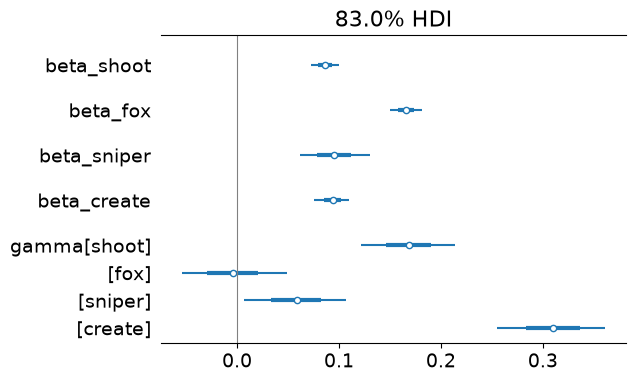

In [10]:
az.plot_forest(idata, var_names=["beta_shoot", "beta_fox", "beta_sniper", "beta_create", "gamma"], combined=True,
               hdi_prob=0.83, figsize=(6, 4))
plt.axvline(0, color="grey", lw=0.8)
plt.show()

## A predictive check

Replicated shots and key passes from the posterior, against the observed seasons. The [write-up](https://examinedalgorithms.com/football_models_with_wyatt/model.html#posterior-predictive-checks) has the fuller set of checks, including leave-one-out calibration.

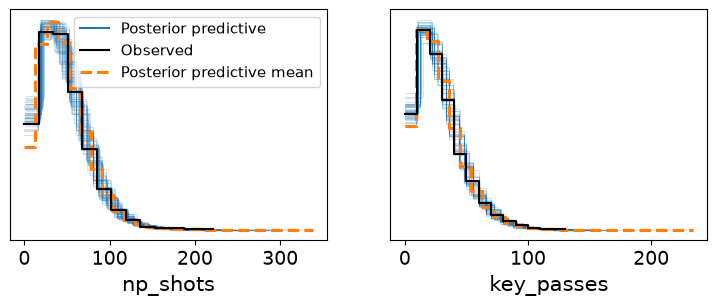

In [11]:
az.plot_ppc(idata, var_names=["np_shots", "key_passes"], num_pp_samples=50, figsize=(9, 3))
plt.show()

## Skill above replacement

SAR is the extra non-penalty goals per 90 a forward would score over a replacement forward, if both played in an average league, for an average team ($\text{TS} = 0$), at an average point in their careers.

The level-field rate multiplies the first three skills: shots per 90, xG per shot, and goals per xG. Finishing shifts each shot's log-odds, so goals per xG depends on the mix of chances. We use one mix for everyone, all shots in the data, and the same second-order approximation as the likelihood: goals per xG $\approx 1 + (V/X)\,\eta$. The published tables use the exact curve, so a few values differ in the third decimal.

In [12]:
post = idata.posterior
stack = lambda v: post[v].stack(s=("chain", "draw")).values
theta = post.theta.stack(s=("chain", "draw")).transpose("player", "skill", "s").values
mu = {k: stack(f"mu_{k}") for k in SKILLS}
beta = {k: stack(f"beta_{k}") for k in SKILLS}
slope = df.fin_var.sum() / df.fin_xg.sum()
print(f"goals per xG ≈ 1 + {slope:.2f} × finishing")

shots90 = np.exp(mu["shoot"] + theta[:, 0])                  # (player, draw)
xg_per_shot = np.exp(mu["fox"] + theta[:, 1])
goals_per_xg = 1 + slope * (mu["sniper"] + theta[:, 2])
level = shots90 * xg_per_shot * goals_per_xg

m = level.mean(axis=1)
pool = (m >= np.quantile(m, 0.4)) & (m <= np.quantile(m, 0.6))
print(f"replacement pool: {pool.sum()} forwards, {level[pool].mean():.3f} goals per 90")

parts = pd.DataFrame({"shots per 90": shots90.mean(1), "xG per shot": xg_per_shot.mean(1),
                      "goals per xG": goals_per_xg.mean(1), "goals per 90": level.mean(1)}, index=names)
pd.concat([parts.loc[["Erling Haaland", "Lionel Messi", "Harry Kane"]],
           parts[pool].mean().rename("replacement pool").to_frame().T]).round(3)

goals per xG ≈ 1 + 0.66 × finishing
replacement pool: 119 forwards, 0.254 goals per 90


,shots per 90,xG per shot,goals per xG,goals per 90
Erling Haaland,3.141,0.192,0.977,0.588
Lionel Messi,4.733,0.108,1.113,0.566
Harry Kane,3.701,0.132,1.075,0.524
replacement pool,2.332,0.114,0.988,0.254


Haaland and Messi reach similar rates by different routes: fewer shots from better places for Haaland, more shots from ordinary places with better finishing for Messi.

SAR subtracts the pool's average rate, draw by draw. PAR does the same with each forward's own teams: add $\beta_k\,\text{TS}$ to the three scoring skills for each of his seasons, compute the rate, and average by minutes. The team lift is PAR's rate minus SAR's, and SAR − PAR is minus the forward's lift relative to the pool's.

In [13]:
def rate(eta_shoot, eta_fox, eta_sniper):
    return np.exp(eta_shoot + eta_fox) * (1 + slope * eta_sniper)

ts = data["ts"][:, None]
row_rate = rate(*(mu[k] + beta[k] * ts + theta[p_idx, j] for j, k in enumerate(SKILLS[:3])))   # (row, draw)
w = df.minutes.to_numpy()
actual = np.zeros_like(level)
np.add.at(actual, p_idx, w[:, None] * row_rate)
actual /= np.bincount(p_idx, weights=w)[:, None]

sar = level - level[pool].mean(axis=0)
par = actual - actual[pool].mean(axis=0)
table = pd.DataFrame({"player": names, "SAR": sar.mean(1), "lo83": np.quantile(sar, .085, 1),
                      "hi83": np.quantile(sar, .915, 1), "PAR": par.mean(1),
                      "team lift": (actual - level).mean(1), "SAR - PAR": (sar - par).mean(1)})
print(f"pool's average team lift: {(actual - level)[pool].mean():.3f} goals per 90")
table.sort_values("SAR", ascending=False).head(10).round(3)

pool's average team lift: 0.007 goals per 90


,player,SAR,lo83,hi83,PAR,team lift,SAR - PAR
569,Erling Haaland,0.333,0.235,0.438,0.488,0.162,-0.155
248,Lionel Messi,0.312,0.251,0.378,0.506,0.201,-0.194
348,Kylian Mbappé,0.309,0.236,0.386,0.509,0.208,-0.201
291,Cristiano Ronaldo,0.306,0.240,0.373,0.484,0.185,-0.178
591,Darwin Núñez,0.303,0.177,0.441,0.410,0.114,-0.106
31,Robert Lewandowski,0.303,0.237,0.371,0.509,0.213,-0.206
90,Sergio Agüero,0.282,0.205,0.364,0.451,0.176,-0.169
249,Luis Suárez,0.272,0.205,0.344,0.453,0.188,-0.181
94,Harry Kane,0.270,0.212,0.332,0.360,0.097,-0.090
232,Zlatan Ibrahimovic,0.265,0.185,0.349,0.399,0.141,-0.134


A SAR of 0.33 goals per 90 is about 11 non-penalty goals over 34 full matches. Changing the replacement pool moves every SAR by the same amount in each draw, so the order stays the same.

## Parameter recovery

Can the model recover skills it was given? We take one draw from the posterior as the truth and fix every parameter at that draw with `pm.do`. We then simulate a dataset from the fixed model and fit a fresh copy of the model to the simulated data. If the model works, the posterior should cover the true skills at about the advertised rate.

In [14]:
k = 1234
truth = {rv.name: post[rv.name].isel(chain=0, draw=k).values for rv in model.free_RVs}
true_theta = post.theta.isel(chain=0, draw=k).values

fixed = pm.do(model, truth)
with fixed:
    sim = pm.sample_prior_predictive(1, var_names=list(observed), random_seed=7).prior_predictive
simulated = {v: sim[v].values[0, 0] for v in observed}

with make_model(simulated):
    idata_sim = pm.sample(**SAMPLE)
print("divergences:", int(idata_sim.sample_stats.diverging.sum()))

Sampling: [finishing, key_passes, log_xg_per_shot, np_shots]


divergences: 0


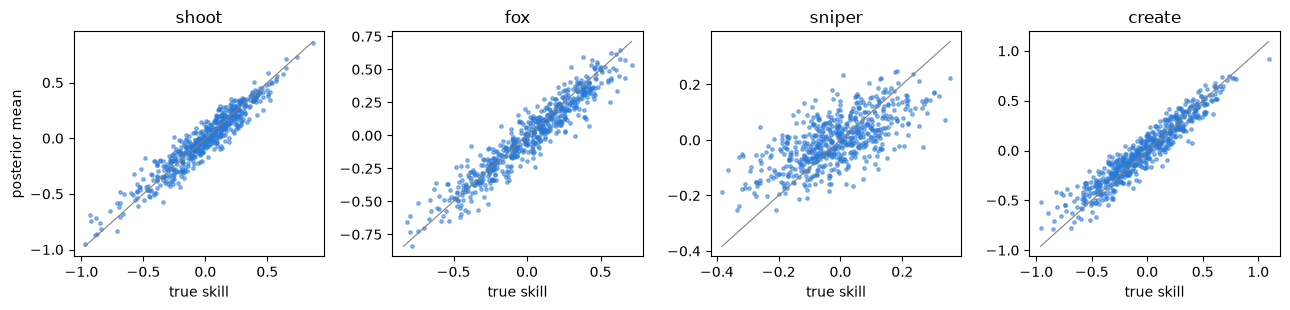

,skill,83% coverage,"corr(estimate, truth)"
0,shoot,0.836,0.952
1,fox,0.833,0.950
2,sniper,0.818,0.665
3,create,0.815,0.950


In [15]:
est = idata_sim.posterior.theta.stack(s=("chain", "draw")).transpose("player", "skill", "s").values
lo, hi = np.quantile(est, [0.085, 0.915], axis=-1)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
rows = []
for j, (skill, ax) in enumerate(zip(SKILLS, axes)):
    t, e = true_theta[:, j], est[:, j].mean(-1)
    ax.scatter(t, e, s=6, alpha=0.5, color="#2a78d6")
    lim = [min(t.min(), e.min()), max(t.max(), e.max())]
    ax.plot(lim, lim, color="grey", lw=0.8)
    ax.set_title(skill)
    ax.set_xlabel("true skill")
    rows.append({"skill": skill, "83% coverage": ((t >= lo[:, j]) & (t <= hi[:, j])).mean().round(3),
                 "corr(estimate, truth)": np.corrcoef(t, e)[0, 1].round(3)})
axes[0].set_ylabel("posterior mean")
plt.tight_layout()
plt.show()
pd.DataFrame(rows)

In [16]:
pd.DataFrame({
    "true": [float(truth[f"beta_{s}"]) for s in SKILLS] + list(truth["gamma"]),
    "estimate": [float(idata_sim.posterior[f"beta_{s}"].mean()) for s in SKILLS]
                + list(idata_sim.posterior.gamma.mean(("chain", "draw")).values),
}, index=[f"beta_{s}" for s in SKILLS] + [f"gamma_{s}" for s in SKILLS]).round(3)

,true,estimate
beta_shoot,0.097,0.097
beta_fox,0.168,0.164
beta_sniper,0.081,0.086
beta_create,0.084,0.097
gamma_shoot,0.223,0.152
gamma_fox,0.004,0.000
gamma_sniper,0.074,0.042
gamma_create,0.295,0.292


Shooting, chance quality and creating are recovered closely, and the 83% intervals cover close to 83% of the true skills. Finishing is recovered least well: a forward's finishing shows only in a few dozen goals a season. The within-player team effects $\beta$ come back within about 0.01. The Mundlak terms $\gamma$ are estimated less precisely, because they rest on differences between players rather than within them: in this run $\gamma$ for shooting comes back at about 0.15 against a true 0.22.